# Nonlinear Equations
## 9/22/26

* relaxation method
* bisection method
* Newton's method
* max and mins of functions



Linear Equations:\
$Ax = v$, where A is a matrix and x, v are vectors

Nonlinear Equations:\
$x = 2 - e^-x$ \
an equation where the variable on one side is equal to some operations that include the variable

### Exercise 6.10 in the notes



Consider the equation x = 1 - e**(-cx), where c is a known parameter. This equation arises in a
variety of situations, including the physics of contact processes and mathematical models of
epidemics.

Write a program to solve this equation for x using the relaxation method for c=2.

Modify your program to calculate the solution for c from 0 to 3 in steps of 0.1 and make a
plot of x as a function of c.

Text(0.5, 1.0, 'c varies from 0 to 3')

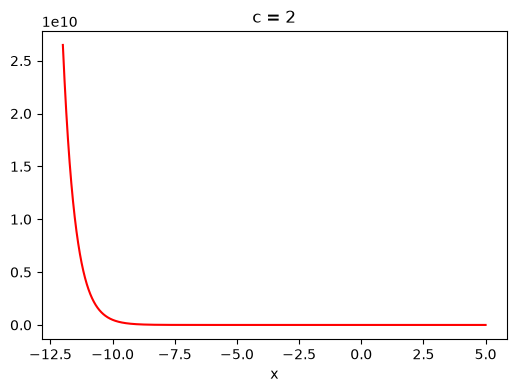

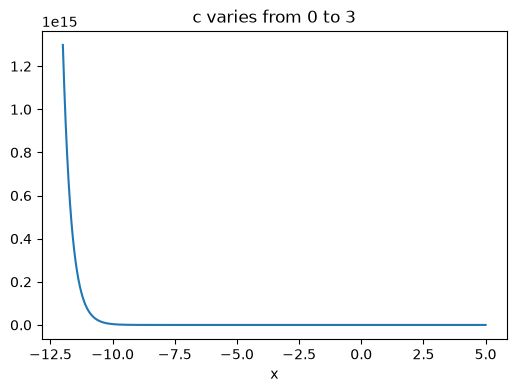

In [52]:
import numpy as np
from matplotlib import pyplot as plt


def func(c, x):
    return x - 1 + np.e**(-c * x)


c1 = 2
step_size = 0.001
xs = np.arange(-12, 5, step_size)


plt.figure(figsize= (6,4))
plt.plot(xs, func(c1, x=xs), color="red")
plt.xlabel("x")
plt.title("c = 2")





cs = np.arange(0, 3, 0.1)

for c in cs:
    vary_c_vals = func(c, xs)

plt.figure(figsize= (6,4))
plt.plot(xs, vary_c_vals)
plt.xlabel("x")
plt.title("c varies from 0 to 3")
#plt.plot(np.argmin(np.abs(vary_c_vals))/step_size, np.min(np.abs(vary_c_vals)))
#print(np.argmin(np.abs(vary_c_vals)), np.min(np.abs(vary_c_vals)))

# GET CODE FROM ALEJANDRA -- MINE IS WRONG

## Relaxation Method for 2 or More Variables

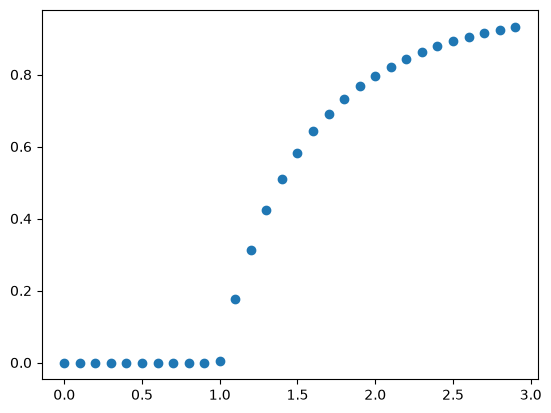

In [53]:
def fxn(x, c) :
    return 1 - np.e**(-c*x)

def relaxation_method(eq, c):
    # Initial guess of y
    y = 10

    # Bc will never be exactly the same, check for very small difference... as
    # long as there is big difference, will keep checking
    error = 999
    while error > 1e-5:
        # Plug in y to find new y
        y1 = eq(y, c)

        # Calculate error (abs value difference between old and, new y)
        error = abs(y1 - y)

        # Set new y to be old y
        y = y1
    return y

# Creates list of c
clist = np.arange(0,3,0.1)
ylist = np.array([])

# Runs the relaxation method for each value of c in clist
for c in clist:
    # Saves each converged y into ylist
    ylist = np.append(ylist, relaxation_method(fxn, c))

# Plots clist vs. ylist
plt.plot(clist, ylist, "o")


What if, instead we have equations for two variables:\
$x = f(x,y), \ \ \ y = g(x,y)$

* the relaxation method works just as well as long as each
equation can be written in a form that gives back the variable.

* This is one of the strengths of the relaxation method, it is
easily extended to many nonlinear equations of multiple
variables.

* We’ll see other methods are not so easily extended to
multiple variables.

# 9/24/26

## More on Relaxation Method

Bisection:

* make our next guess halfway in between two of our previous guesses to get a more accurate guess
* **bisection works by finding roots**
* ******with a continuous function where one side is positive and one side is negative, there must be somewhere where the function crosses 0. we take halfway between the two points, and if the two endpoints are still positive and negative respectively, do it again. keep going until both are positive or both are negative, and then switch. choose some accuracy within whcih you'd like to be.


From Notes: \
**OUTLINE**
1. Given an initial pair of points, x1,x2, check that f(x1) and f(x2)
have opposite signs. Choose an accuracy, ε.
2. Calculate the midpoint x’=1/2(x1 + x2) and f(x’).
3. If f(x’) has the same sign as f(x1) replace x1=x’. Otherwise
x2=x’.
4. If |x1 - x2| > ε repeat from step 2. Otherwise calculate
1/2(x1+x2) again and that is your answer.
➤ As with relaxation, bisection improves exponentially. With
each step you are twice as close to a solution.


Shortcomings:
* Bisection does have a number of shortcomings, most obviously
if f(x1) and f(x2) have the same sign then you can’t find a root.
This maybe because there is no root between these values, or
because there are an even number, or because the function just
touches zero but doesn’t cross it.
* Thus bisection works best if you know enough about your
function to know some places where it is positive and negative.
* If you are looking for a root near a particular value of x, start
with x1 and x2 near that value. If they don’t bracket the root,
then keep doubling the distance to x1 and x2 till they do
bracket the root.
* A final problem with bisection is that it only work for single
equations of one variable.
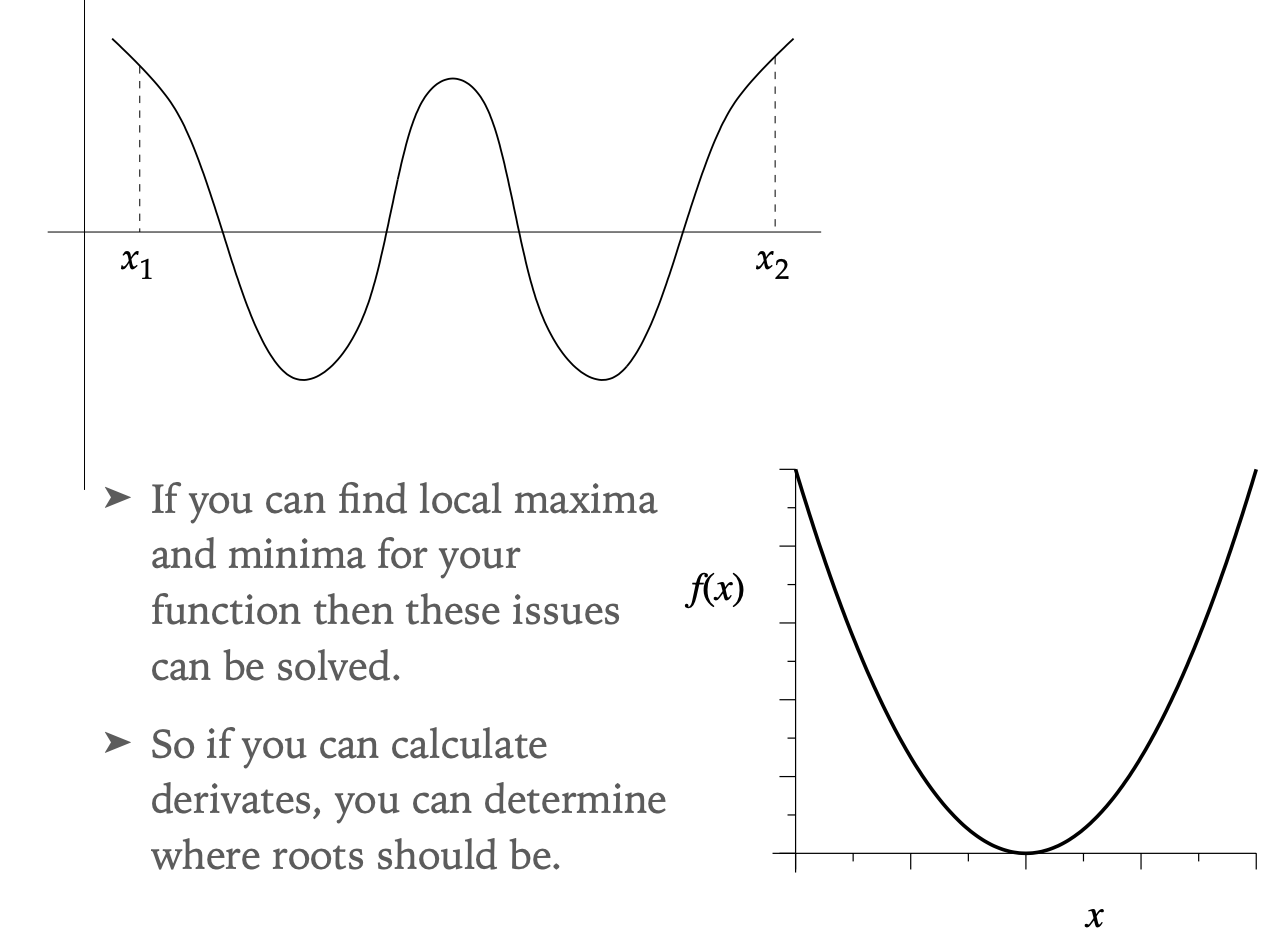

## Newton's Method
### separte method from Bisection

* **involves taking derivatives**
* The fastest way to find roots of an equation
* Newton’s method is similar to bisection, except we use the functions derivative to estimate where we should make our next evaluation instead of the halfway point.
* Using the derivative we should end up with a closer guess,
though in some cases this doesn’t work.
* Note that if the function was a line then evaluating it at any point and using the slope to determine where it crosses zero would work exactly.

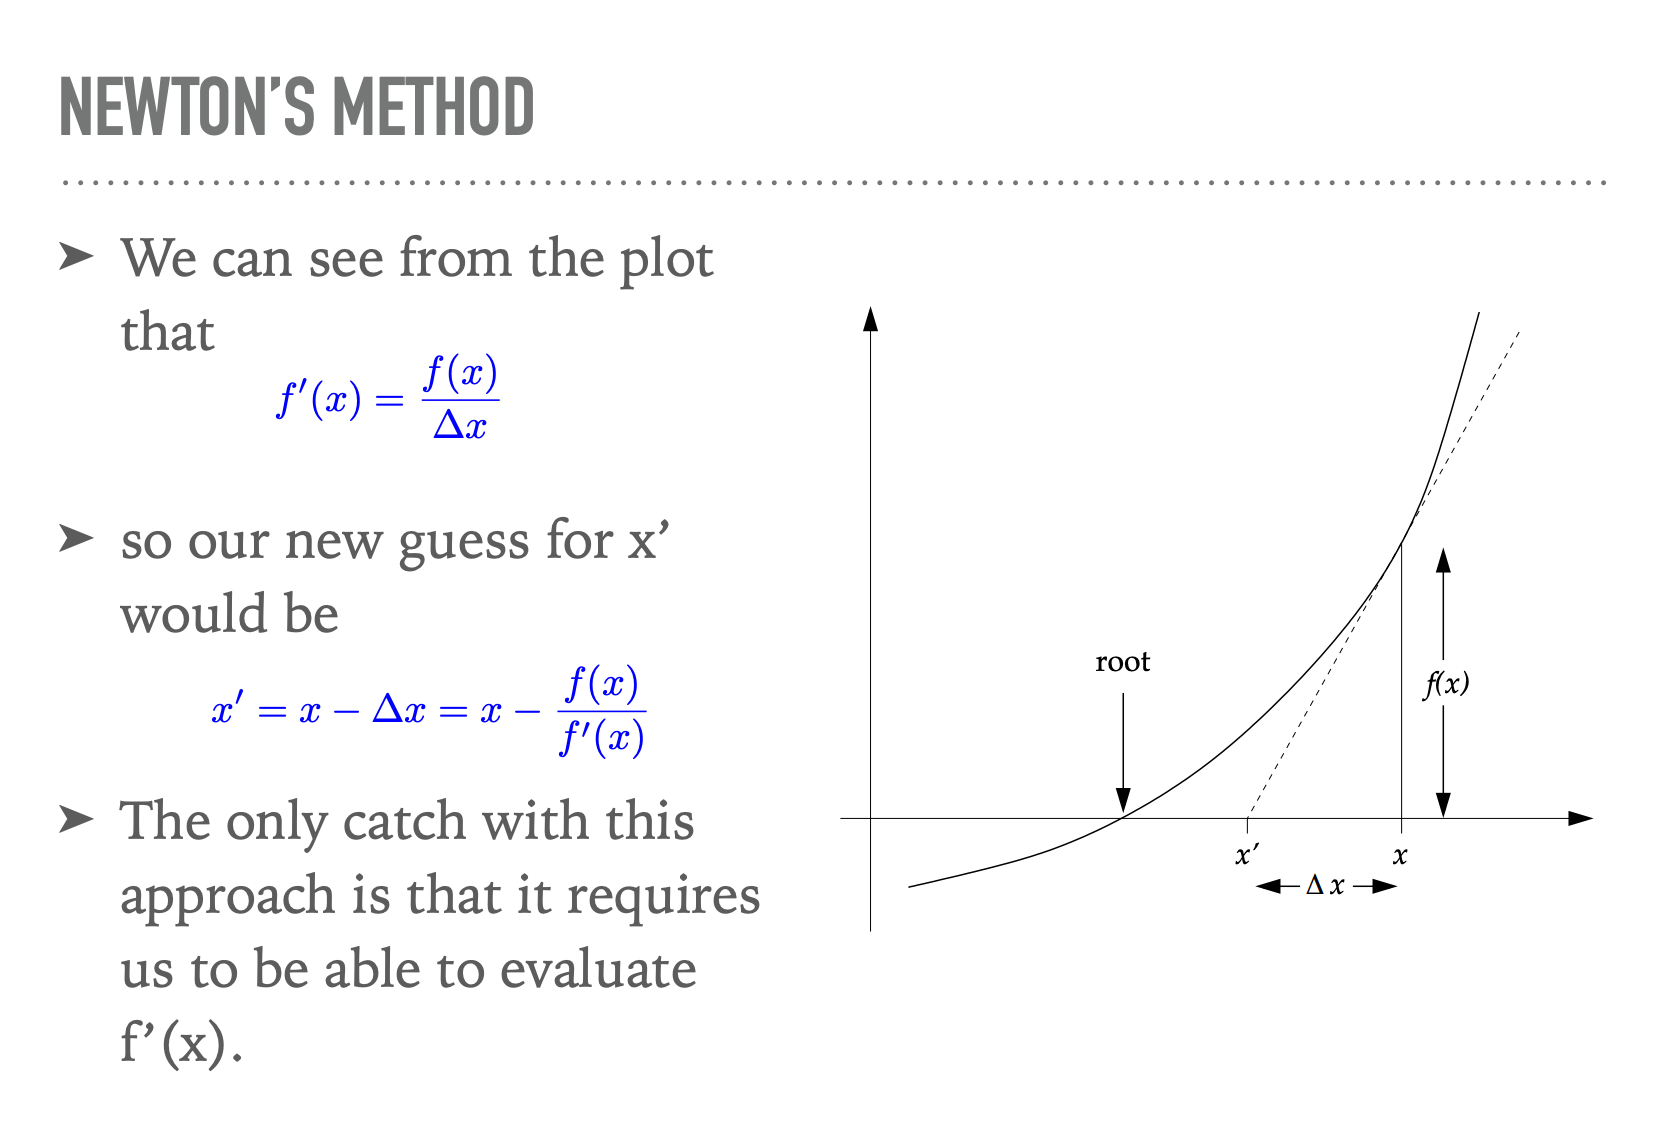

## Exercise 6.15

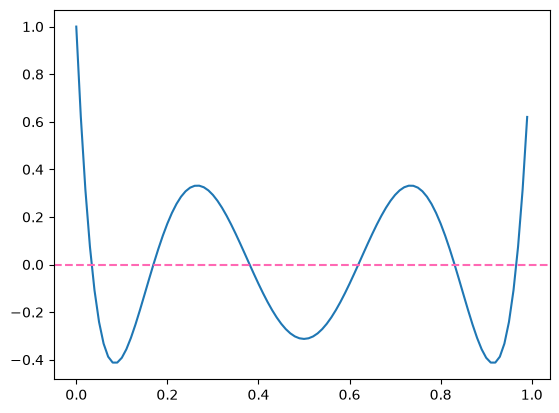

In [15]:
import numpy as np
from matplotlib import pyplot as plt

def P_of_x(x, a1, a2, a3, a4, a5, a6, a7):
    return a1*x**6 + a2*x**5 + a3*x**4 + a4*x**3 + a5*x**2 + a6*x + a7

def deriv_P(x, a1, a2, a3, a4, a5, a6):
    return 6*a1*x**5 + 5*a2*x**4 + 4*a3*x**3 + 3*a4*x**2 + 2*a5*x + a6

a1 = 924
a2 = -2772
a3 = 3150
a4 = -1680
a5 = 420
a6 = -42
a7 = 1

x_vals = np.arange(0, 1, 0.01)
y_vals = P_of_x(x_vals, a1, a2, a3, a4, a5, a6, a7)
plt.plot(x_vals, y_vals)
plt.axhline(y=0, color="hotpink", linestyle="--")
# plt.axvline(x=0.12, color="hotpink")
plt.show()



In [31]:
"""
point1 = [0.02, 0.05]
point2 = [0.13, 0.22]
point3 = [0.37, 0.43]
point4 = [0.6, 0.65]
point5 = [0.8, 0.86]
point6 = [0.92, 1.0]
"""


point_range = [0.02, 0.13, 0.37, 0.6, 0.8, 0.92]
real_points = []
accuracy = 1e-10

for x in point_range:
    #starting points
    pt_1 = 0
    error = 1

    # solving
    f = P_of_x(x, a1, a2, a3, a4, a5, a6, a7)
    f_prime = deriv_P(x, a1, a2, a3, a4, a5, a6)

    while error > accuracy:
        x_prime = x - f/f_prime
        error = np.abs(x_prime - x)
        x = x_prime
        # print(x)

    np.append(real_points, x)

            #x_prime = x - P_of_x(x, a1, a2, a3, a4, a5, a6, a7) / deriv_P(x, a1, a2, a3, a4, a5, a6)
                #if x_prime < accuracy:
                #    print("stop")


# answer = solve(point1)

KeyboardInterrupt: 